# Frequency-band experiment: 3.5 GHz vs 28 GHz

Interactive companion to `scripts/run_experiment.py` (same library, same config, same outputs).

**What is simulated:** one transmitter (44 dBm, isotropic, rooftop height) in Sionna's built-in Munich scene,
three receivers at 1.5 m (one line-of-sight, two behind buildings). For every band only `scene.frequency` changes;
geometry, positions and power stay the same. Sionna RT ray-traces LoS, specular reflections, refraction and
diffraction (max depth 5) and evaluates frequency-dependent ITU-R P.2040 material properties.

**Order matters:** `sionna_stack.backend.init()` selects the Mitsuba variant (CUDA/OptiX or LLVM) *before*
`sionna.rt` is imported.

In [1]:
from sionna_stack import backend
info = backend.init()   # prints the active backend

Active backend : CUDA/OptiX (GPU)
Mitsuba variant: cuda_ad_mono_polarized
WSL2           : True
GPU / driver   : NVIDIA GeForce RTX 5080 / 591.86
OptiX source   : user-level Linux driver files in /home/gavin/.local/lib/nvidia-optix-590.48.01
Versions       : sionna 2.1.0, sionna-rt 2.1.0, mitsuba 3.9.1, drjit 1.5.0, torch 2.14.0, python 3.12.3


In [2]:
from pathlib import Path
from IPython.display import Image, Markdown, display
import pandas as pd
from sionna_stack.config import load_config, band_label, band_slug
from sionna_stack import experiment as ex

cfg = load_config("../configs/munich_frequency.toml")
# cfg.bands_ghz = [0.7, 3.5, 28.0]; cfg.extrapolate_materials = True   # optional 700 MHz (extrapolated materials!)
print(cfg.scene, cfg.bands_ghz)

builtin:munich [3.5, 28.0]


## 1. Run the experiment (writes `outputs/<experiment>/<run_id>/`)

In [3]:
run_dir = ex.run_experiment(cfg, out_root="../outputs")

Active backend : CUDA/OptiX (GPU)
Mitsuba variant: cuda_ad_mono_polarized
WSL2           : True
GPU / driver   : NVIDIA GeForce RTX 5080 / 591.86
OptiX source   : user-level Linux driver files in /home/gavin/.local/lib/nvidia-optix-590.48.01
Versions       : sionna 2.1.0, sionna-rt 2.1.0, mitsuba 3.9.1, drjit 1.5.0, torch 2.14.0, python 3.12.3
Run directory  : ../outputs/munich_frequency/20260927-164057

=== 3.5 GHz ===
  timings: paths_s=0.15, radio_map_s=0.05, render_s=8.81

=== 28 GHz ===
  timings: paths_s=0.06, radio_map_s=0.04, render_s=4.22

| band_ghz | rx | expected | los | num_paths | strongest_path_gain_db | total_path_gain_db | rx_power_dbm | rms_delay_spread_ns | mean_excess_delay_ns | num_paths_with_diffraction |
|---|---|---|---|---|---|---|---|---|---|---|
| 3.5 | rx_los | LOS | True | 203 | -81.8 | -81.1 | -37.1 | 124.3 | 43.9 | 180 |
| 3.5 | rx_nlos | NLOS | False | 8 | -113.1 | -110.5 | -66.5 | 11.4 | 8.6 | 3 |
| 3.5 | rx_nlos_far | NLOS | False | 9 | -107.1 | -106.0

## 2. Radio maps with a shared colour scale (+ difference map)

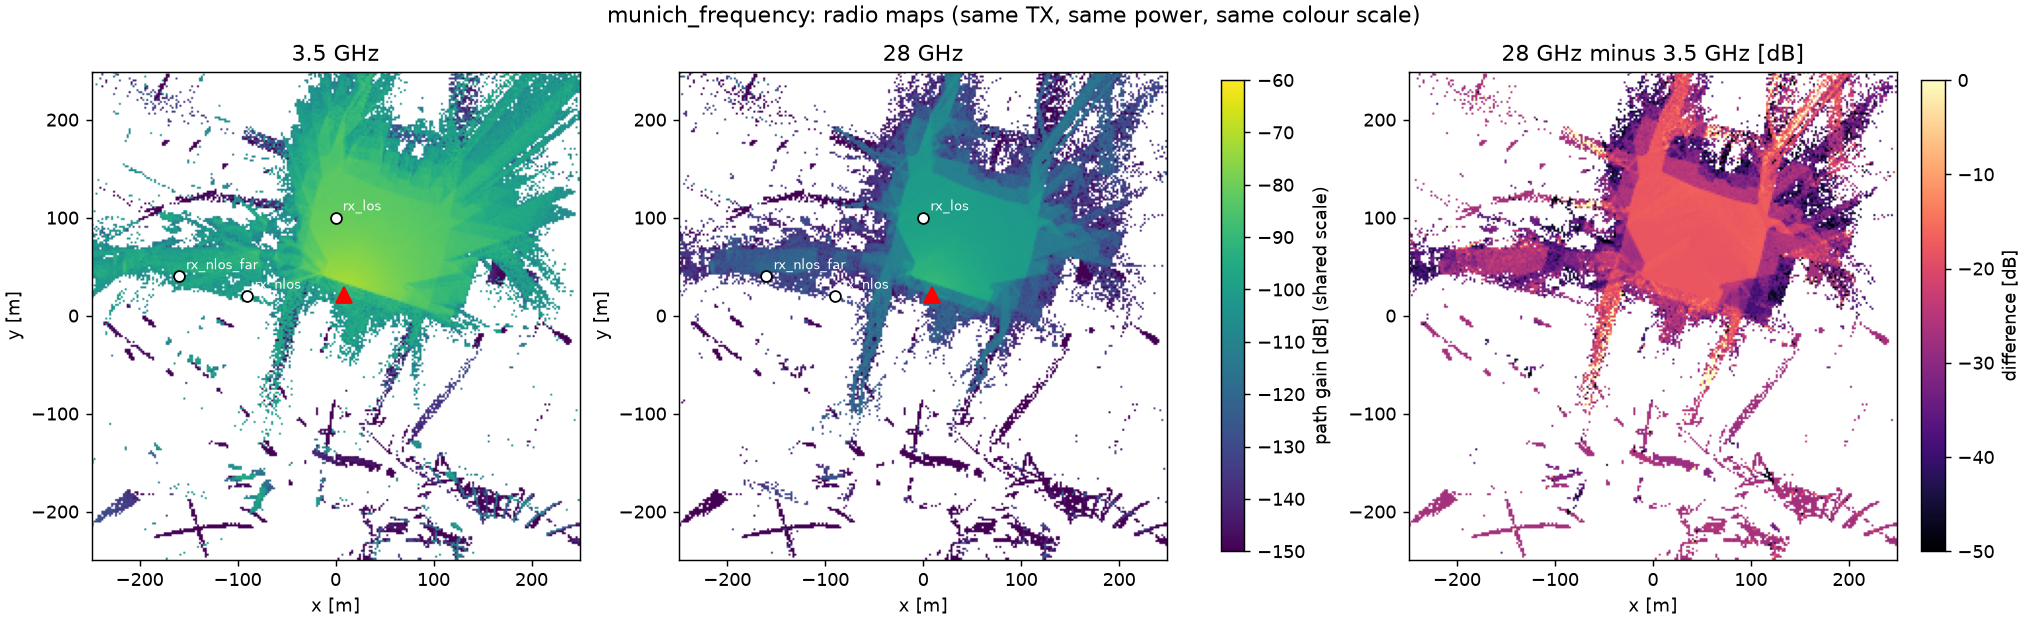

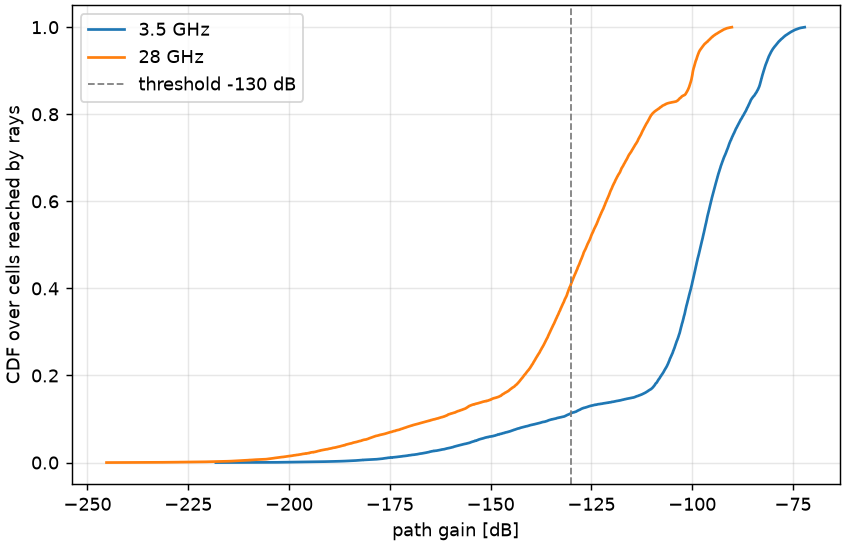

In [4]:
display(Image(filename=run_dir / "comparison_radio_maps.png"))
display(Image(filename=run_dir / "path_gain_cdf.png", width=600))

## 3. Sionna renders per band: scene with radio-map overlay, and ray paths

### 3.5 GHz

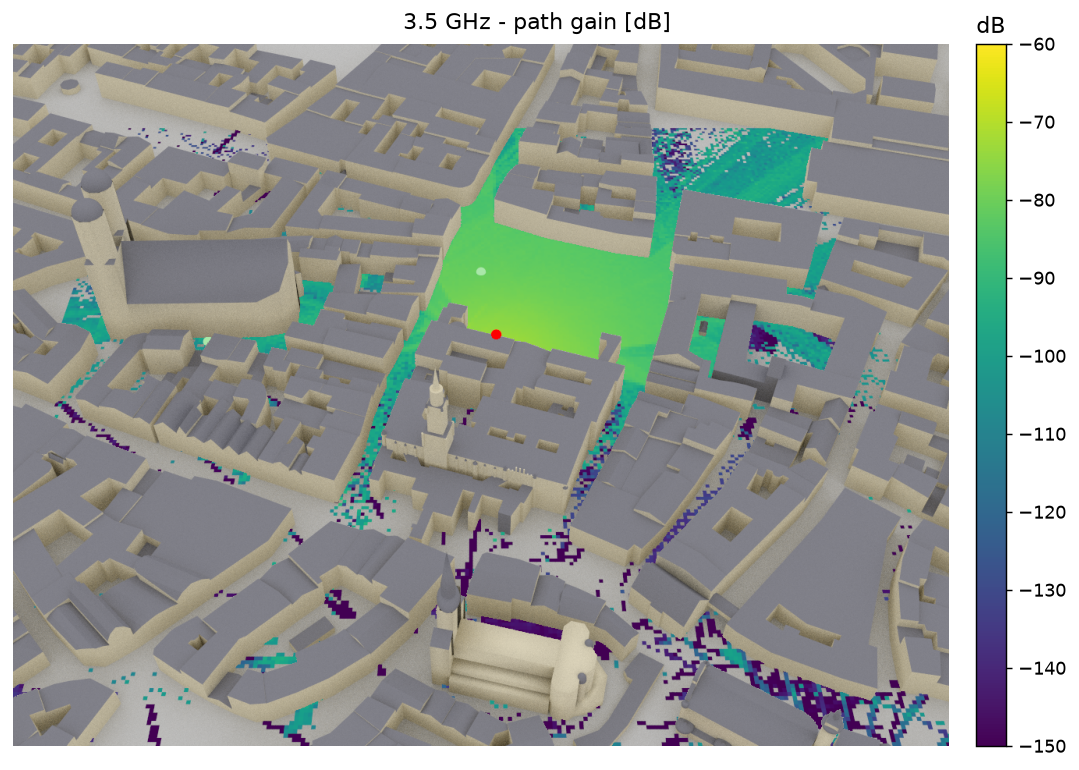

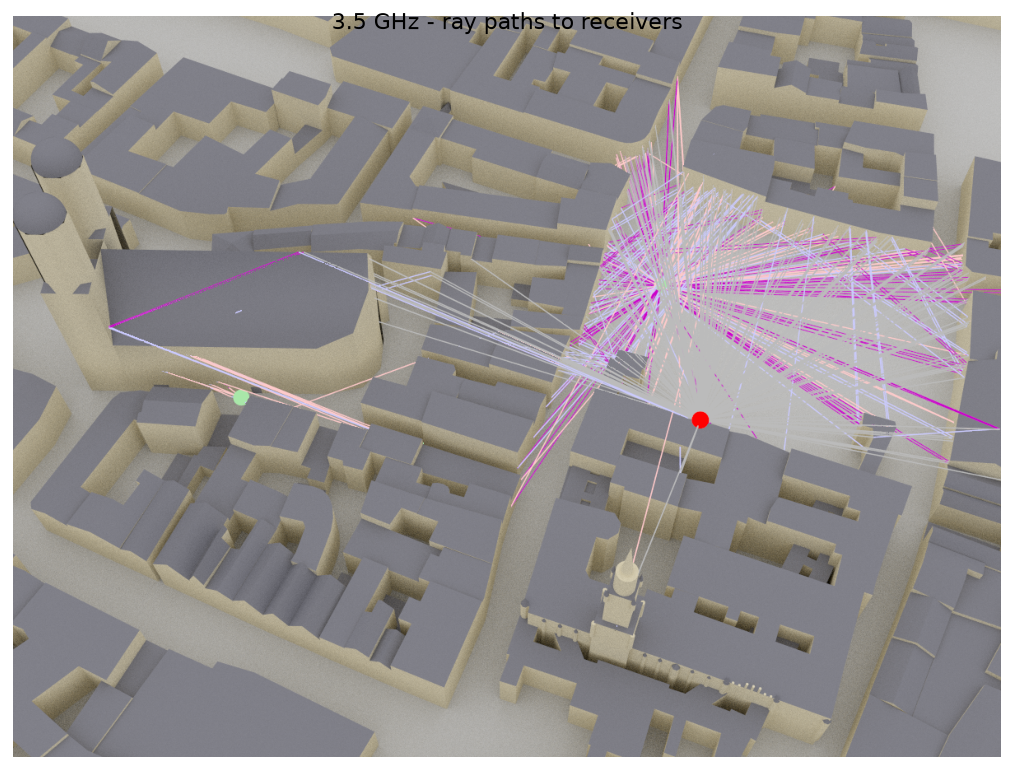

### 28 GHz

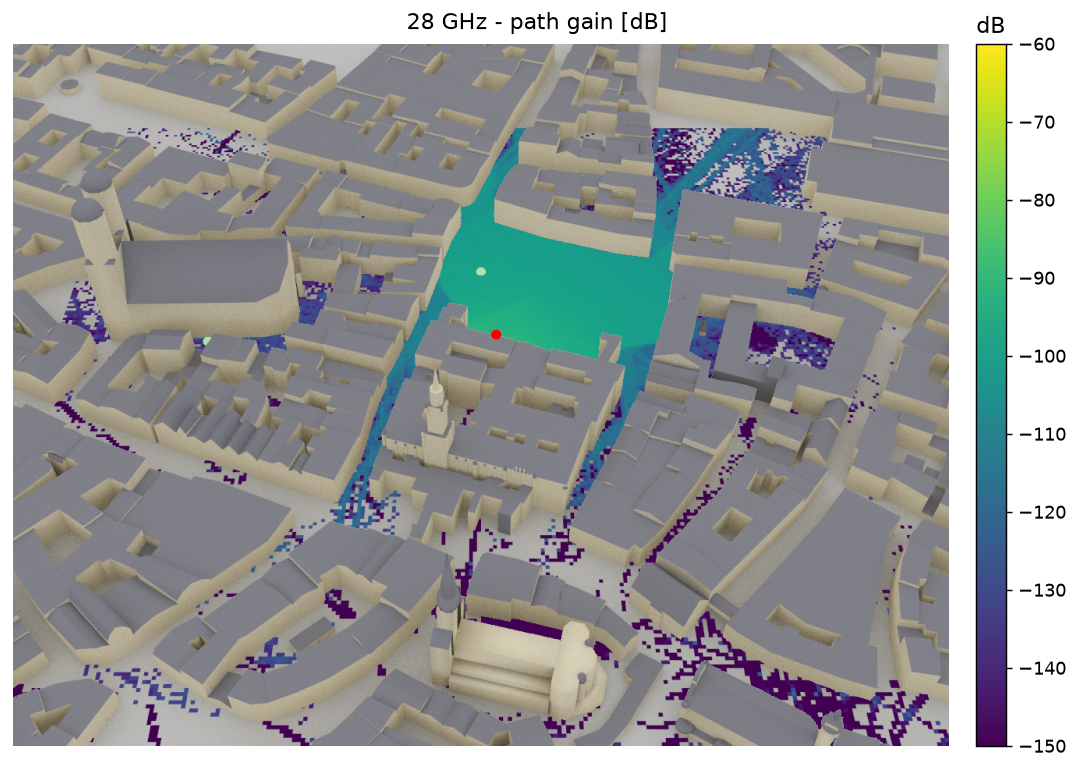

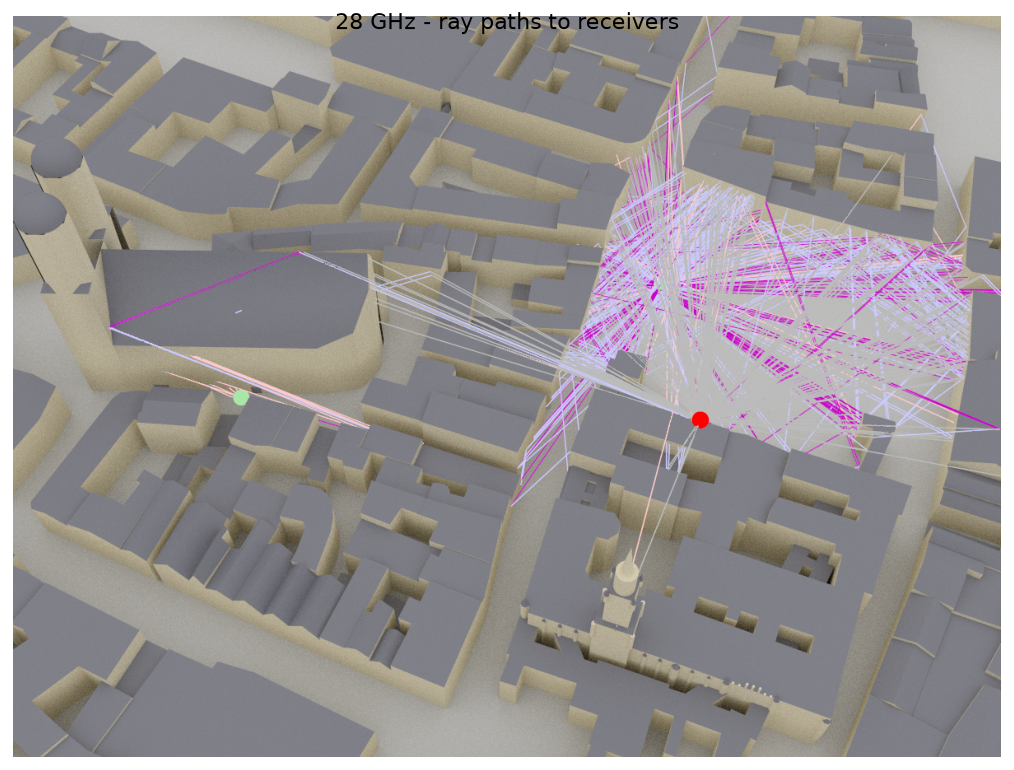

In [5]:
for ghz in cfg.bands_ghz:
    d = run_dir / f"band_{band_slug(ghz)}"
    display(Markdown(f"### {band_label(ghz)}"))
    display(Image(filename=d / "scene_radio_map.png", width=800))
    display(Image(filename=d / "scene_paths.png", width=800))

## 4. Per band and receiver: number of paths, strongest path gain, delay spread

,band_ghz,rx,expected,los,num_paths,strongest_path_gain_db,total_path_gain_db,rx_power_dbm,rms_delay_spread_ns,num_paths_with_diffraction
0,3.5,rx_los,LOS,True,203,-81.8,-81.1,-37.1,124.3,180
1,3.5,rx_nlos,NLOS,False,8,-113.1,-110.5,-66.5,11.4,3
2,3.5,rx_nlos_far,NLOS,False,9,-107.1,-106.0,-62.0,118.8,2
3,28.0,rx_los,LOS,True,261,-99.8,-98.6,-54.6,122.4,231
4,28.0,rx_nlos,NLOS,False,9,-146.2,-143.6,-99.6,5.3,4
5,28.0,rx_nlos_far,NLOS,False,10,-148.6,-144.9,-100.9,5.8,4


,band_ghz,cells_total,cells_reached_pct,coverage_pct_above_-130dB,median_path_gain_db_reached,p10_path_gain_db_reached
0,3.5,62500,36.3,32.2,-97.8,-134.4
1,28.0,62500,33.4,19.7,-126.0,-163.7


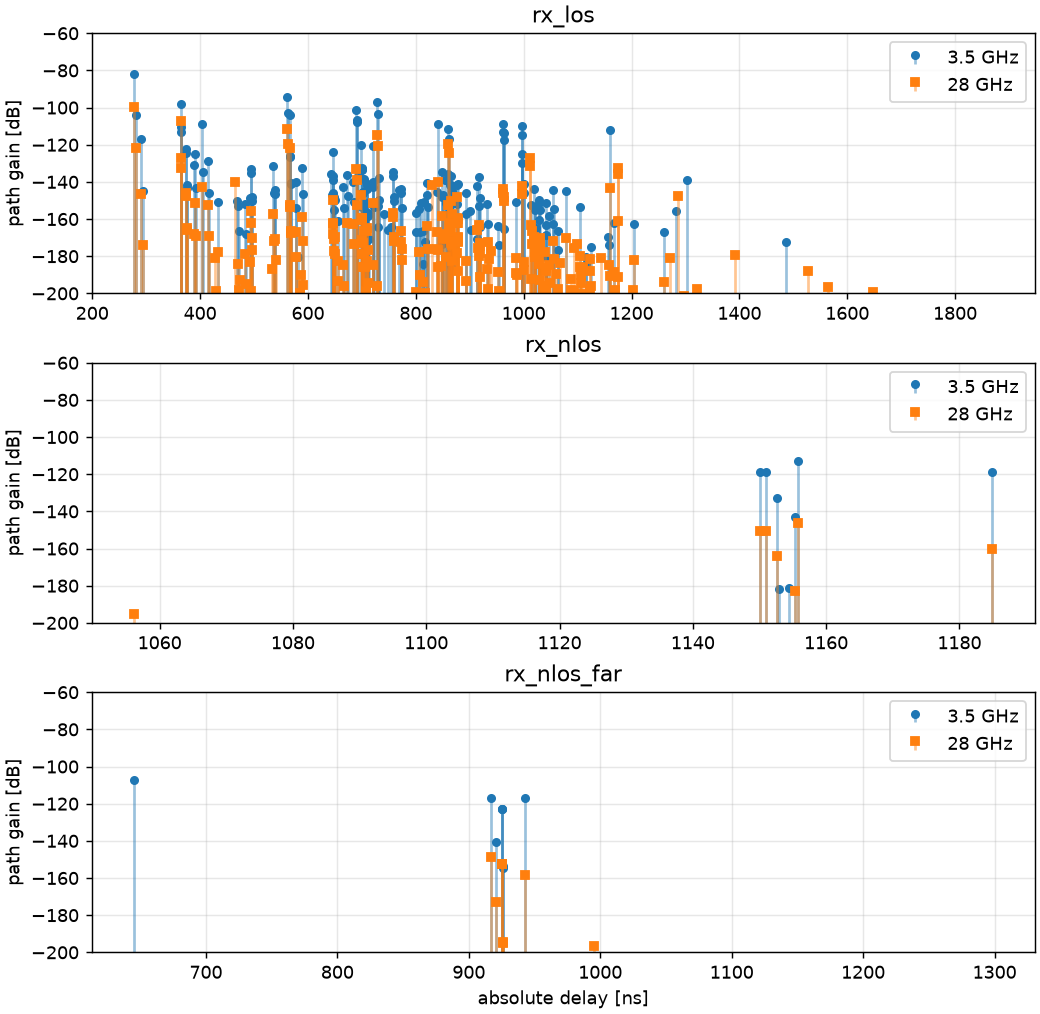

In [6]:
df = pd.read_csv(run_dir / "metrics.csv")
cols = ["band_ghz", "rx", "expected", "los", "num_paths", "strongest_path_gain_db", "total_path_gain_db",
        "rx_power_dbm", "rms_delay_spread_ns", "num_paths_with_diffraction"]
display(df[cols].round(1))
display(pd.read_csv(run_dir / "radio_map_stats.csv").round(1))
display(Image(filename=run_dir / "power_delay_profiles.png", width=700))

## 5. Interactive 3-D preview (`scene.preview`)

Rotate: left-drag · zoom: scroll · pan: right-drag. Uses pythreejs/ipywidgets inside JupyterLab.
The scene below is rebuilt at one band so the paths and radio map objects are live.

In [7]:
scene = ex.build_scene(cfg)
ghz = 3.5
ex.set_band(scene, cfg, ghz)
paths = ex.compute_paths(scene, cfg)
rm = ex.compute_radio_map(scene, cfg)
scene.preview(paths=paths, radio_map=rm, rm_vmin=cfg.radio_map.vmin_db, rm_vmax=cfg.radio_map.vmax_db,
              clip_at=40)

In [8]:
ghz = 28.0
ex.set_band(scene, cfg, ghz)
paths28 = ex.compute_paths(scene, cfg)
rm28 = ex.compute_radio_map(scene, cfg)
scene.preview(paths=paths28, radio_map=rm28, rm_vmin=cfg.radio_map.vmin_db, rm_vmax=cfg.radio_map.vmax_db,
              clip_at=40)

## Reading the results

* **LOS receiver:** the 28 GHz / 3.5 GHz gap is ≈ 20·log10(28/3.5) ≈ 18 dB, i.e. the free-space (Friis)
  term for isotropic antennas (effective aperture ∝ λ²).
* **NLOS receivers:** the gap grows well beyond 18 dB because diffraction loss increases with frequency
  and fewer multipath components survive; coverage behind buildings collapses at 28 GHz.
* **Delay spread** depends on which paths survive; compare the power-delay profiles above.